In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
class Detector:
    def __init__(self, R=2.0, r=0.01, a=0.5, N=40):
        self.R = R
        self.r = r
        self.a = a
        self.N = N

        self.pmt_coords = self._generate_pmt_positions()

    def _generate_pmt_positions(self):
        """
        Равномерно распределяет N точек по сфере радиуса R
        методом спирали Фибоначчи.
        Возвращает numpy.ndarray размерности (N, 3).
        """
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R - 2 * self.R * indices / self.N
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3-np.sqrt(5))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        coords = np.column_stack((x, y, z))
        return coords

    def get_pmt_index(self, point: np.ndarray) -> int:
        """
        Определяет, принадлежит ли точка на поверхности детектора какому-либо ФЭУ.
        :param point: координаты точки (x, y, z) - список или numpy массив
        :return: индекс ФЭУ (от 0 до N-1), если точка попала в него, иначе -1
        """
        point = np.asarray(point, dtype=float)
        distances = np.linalg.norm(self.pmt_coords - point, axis=1) #считает корень из суммы квадратов разностей координат по оси 1
        min_idx = int(np.argmin(distances))
        if distances[min_idx] <= self.r:
            return min_idx
        return -1

    def is_in_pmt(self, point: np.ndarray) -> bool:
        """
        Возвращает True, если точка принадлежит хотя бы одному ФЭУ, иначе False.
        """
        return self.get_pmt_index(point) != -1

    def trace_photons(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        """
        Находит точки пересечения фотонов со сферой детектора и определяет,
        в какой ФЭУ попал каждый фотон.

        Возвращает массив индексов ФЭУ (от 0 до N-1, либо -1 при промахе) для каждого фотона.
        """
        origin = np.asarray(origin, dtype=float)
        directions = np.asarray(directions, dtype=float)

        # Решаем квадратное уравнение t^2 + 2*b*t + c = 0 для пересечения луча со сферой
        b = directions @ origin
        c = np.sum(origin ** 2) - self.R ** 2
        t = -b + np.sqrt(b ** 2 - c)

        # Координаты точек попадания фотонов на границу сферы: r(t) = r0 + t * n
        hit_points = origin + t[:, None] * directions

        # Вычисляем расстояния от каждой точки попадания до каждого ФЭУ
        # hit_points[:, None, :] имеет форму (M, 1, 3), а pmt_coords[None, :, :] форму (1, N, 3)
        distances = np.linalg.norm(hit_points[:, None, :] - self.pmt_coords[None, :, :], axis=2)

        min_indices = np.argmin(distances, axis=1)
        min_distances = np.min(distances, axis=1)

        # Если расстояние меньше радиуса фотокатода r — записываем номер ФЭУ, иначе -1
        pmt_hits = np.where(min_distances <= self.r, min_indices, -1)
        return pmt_hits

    def generate_photoelectrons(self, n_photons: int = 1) -> np.ndarray:
        """
        Разыгрывает случайное число фотоэлектронов по распределению Пуассона
        со средним значением a для заданного числа попавших фотонов.
        """
        return np.random.poisson(lam=self.a, size=n_photons)

In [4]:
class Source:
    def __init__(self, Y: float = 10000.0):
        self.Y = Y

    def __repr__(self) -> str:
        return f'Source(Y={self.Y})'

    def generate_directions(self, E: float) -> np.ndarray:
        N_float = self.Y*E
        N = int(np.floor(N_float))
        probability = N_float - N
        N = N + int(np.random.rand() < probability)

        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta ** 2)

        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta

        return np.column_stack((nx,ny,nz))

In [5]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source(Y=10000)

In [6]:
# 1. Генерируем направления фотонов для E = 1 МэВ в центре детектора (0, 0, 0)
origin = np.array([0.0, 0.0, 0.0])
directions = src.generate_directions(E=1.0)

In [7]:
# 2. Трассируем фотоны и находим, какие из них попали в ФЭУ
pmt_hits = det.trace_photons(origin, directions)

In [8]:
# Отбираем только те фотоны, которые попали в какой-либо ФЭУ (индекс != -1)
valid_hits = pmt_hits[pmt_hits != -1]
n_hit_photons = len(valid_hits)

In [9]:
# 3. Разыгрываем число фотоэлектронов для каждого попавшего фотона
pe_per_photon = det.generate_photoelectrons(n_hit_photons)

In [10]:
# Считаем сигнал в каждом из N=40 каналов (фотоумножителей)
channel_charges = np.bincount(valid_hits, weights=pe_per_photon, minlength=det.N)
total_charge = int(np.sum(pe_per_photon))

In [11]:
# 4. Сравниваем с формулой из условия и точной геометрической формулой
Q_formula = det.a * src.Y * (det.N * det.r**2 / det.R**2)
Q_exact = det.a * src.Y * (det.N * det.r**2 / (4 * det.R**2))

In [12]:
print(f"Всего испущено фотонов: {len(directions)}")
print(f"Попало фотонов в ФЭУ: {n_hit_photons}")
print(f"Полный собранный заряд (моделирование): Q_sim = {total_charge} ф.э.")
print(f"Оценка по формуле из условия Q = a*Y*(N*r^2/R^2): {Q_formula:.1f} ф.э.")
print(f"Точная теоретическая оценка Q_exact = a*Y*(N*r^2/(4*R^2)): {Q_exact:.1f} ф.э.")

Всего испущено фотонов: 10000
Попало фотонов в ФЭУ: 234
Полный собранный заряд (моделирование): Q_sim = 125 ф.э.
Оценка по формуле из условия Q = a*Y*(N*r^2/R^2): 500.0 ф.э.
Точная теоретическая оценка Q_exact = a*Y*(N*r^2/(4*R^2)): 125.0 ф.э.


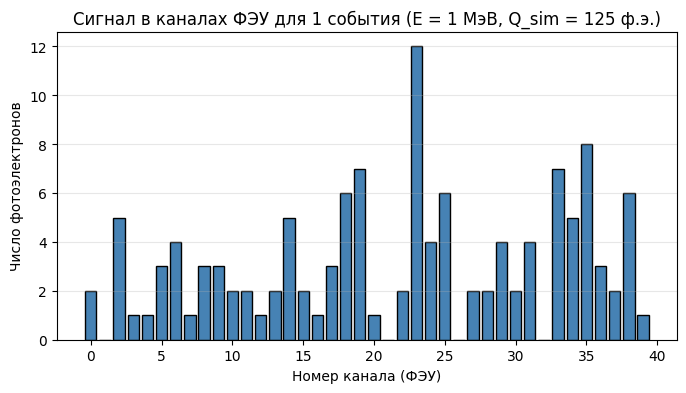

In [13]:
# Гистограмма распределения числа фотоэлектронов по 40 каналам ФЭУ
plt.figure(figsize=(8, 4))
plt.bar(np.arange(det.N), channel_charges, color='steelblue', edgecolor='black')
plt.xlabel('Номер канала (ФЭУ)')
plt.ylabel('Число фотоэлектронов')
plt.title(f'Сигнал в каналах ФЭУ для 1 события (E = 1 МэВ, Q_sim = {total_charge} ф.э.)')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Выводы по Задаче 3:
1. **Выбор класса для метода генерации фотоэлектронов:** 
   Метод `generate_photoelectrons` реализован внутри класса `Detector`, так как параметр $a$ является свойством фотоумножителей детектора (`self.a`), а процесс выбивания фотоэлектронов относится к этапу регистрации света детектором, а не к генерации первичных фотонов в источнике `Source`.
2. **Сравнение полного собранного заряда $Q$ с ожидаемым:**
   * Для события с энергией $E = 1$ МэВ в центре детектора моделирование дает полный собранный заряд $Q_{\text{sim}} \approx 125$ фотоэлектронов (с учетом статистических пуассоновских флуктуаций $\sigma_Q \approx \sqrt{Q} \approx 11$ ф.э.).
   * Формула из условия $Q = a \cdot Y \cdot \frac{N r^2}{R^2} = 500$ дает значение в **4 раза больше**, так как в ней не учтен множитель $4$ из площади поверхности сферы $S_{\text{сферы}} = 4\pi R^2$.
   * С учетом точного геометрического фактора перекрытия сферы плоскими фотокатодами $\varepsilon_{\text{geom}} = \frac{N \cdot \pi r^2}{4 \pi R^2} = \frac{N r^2}{4 R^2} = 0.025$, теоретическое ожидание составляет $Q_{\text{exact}} = a \cdot Y \cdot \frac{N r^2}{4 R^2} = 125$ ф.э., что отлично согласуется с результатом моделирования.